# Fig. 1: continental configurations

In [1]:
from helpers import *
from numpy.polynomial.legendre import leggauss
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs

def gaussian_grid(res):
    # latitudes are roots of the Legendre polynomial of order nlat
    # (see https://confluence.ecmwf.int/display/OIFS/1%20Gaussian%20grids)
    nlat, nlon = {"T21": (32, 64), "T42": (64, 128)}[res]
    mu = leggauss(nlat)[0][::-1] # sin(latitude), south to north
    lats = np.degrees(np.arcsin(mu))
    lons = np.linspace(0, 360, nlon, endpoint=False)
    return lats, lons

def read_service(filepath):
    # reads a PlaSim surface file (.sra) and returns the 2D field
    with open(filepath, "r", encoding="ascii") as f:
        nlon, nlat = [int(x) for x in f.readline().split()[4:6]]
        data = [float(x) for line in f for x in line.split()]
    return np.array(data).reshape(nlat, nlon)

In [2]:
res = "T42"

cases = [
    ("Modern (0 Ma)", "0Ma_flat"),
    ("Carboniferous (300 Ma)", "300Ma_flat"),
    ("Neoproterozoic (720 Ma, Mer21)", "720Ma_Mer21"),
    ("Neoproterozoic (720 Ma, Li23)", "720Ma_Li23"),
]

lsm_fields = {}
for label, topo in cases:
    lsm_fields[label] = read_service(f"topography/surface_files/{topo}/{res}/N064_surf_0172.sra")

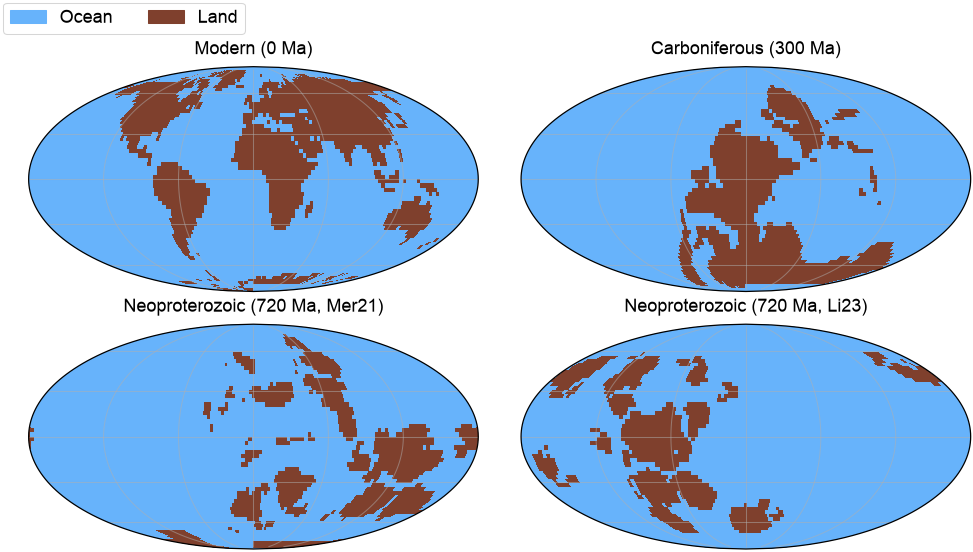

In [3]:
sea_color = "#67B3FB"
land_color = "#7F402D"

lats, lons = gaussian_grid(res=res)
lon2d, lat2d = np.meshgrid(lons, lats)
cmap = ListedColormap([sea_color, land_color])

fig, axes = plt.subplots(2, 2, figsize=(FULL_WIDTH, 3.6), subplot_kw={"projection": ccrs.Mollweide()})

for ax, (label, lsm) in zip(axes.flat, lsm_fields.items()):
    ax.set_global()
    ax.pcolormesh(lon2d, lat2d, lsm, transform=ccrs.PlateCarree(), cmap=cmap, vmin=0, vmax=1, rasterized=True)
    ax.set_title(label)
    gl = ax.gridlines(linewidth=0.5, alpha=0.5)
    gl.xformatter = mticker.NullFormatter()
    gl.yformatter = mticker.NullFormatter()

legend_handles = [
    mpatches.Patch(color=sea_color, label="Ocean"),
    mpatches.Patch(color=land_color, label="Land"),
]
fig.legend(handles=legend_handles, loc="lower left", ncol=2, bbox_to_anchor=(0, 0.98))

fig.tight_layout()
plt.savefig("figs/maps.pdf", bbox_inches="tight")
plt.show()